# Inverse Noise/SNR Sweep

Runs `wCSET`, `CSET`, `MCE`, `MNE`, `sLORETA` and `dSPM` on every run of the noise/SNR
sweep dataset (`sub-simf10-noisesweep`, generated via
`mindmap.analysis.simulation.generate_simulation_dataset` -- see
`tutorials/analysis/simulations/simulation_spike.ipynb`'s "Noise/SNR sweep dataset"
section) and scores each method's accuracy as a function of `target_snr`. Companion to
`inverse-simf.ipynb` (single run, all solvers) and `harmonic-prior-tuning.ipynb` (one
solver's hyperparameter swept across runs) -- this notebook instead sweeps `target_snr`
across runs, with `method` as the second axis.

The dataset also contains a noise-only condition (`target_snr=NaN`, zero-amplitude
signal), which this notebook does not evaluate: the low end of the SNR sweep already
covers "signal indistinguishable from noise" without the added complexity of a
noise-only condition (whose noise-free `gold` is exactly zero everywhere, so there's no
well-defined rising phase/peak to score against).

`generate_simulation_dataset` only writes `simulation_index.tsv` once *after* every run
in the sweep has completed (see `mindmap/analysis/simulation/pipeline.py`), so a
missing/stale index there means the dataset generation isn't finished yet. This notebook
is written against that file's expected schema and left **unexecuted** for that reason --
run it once the index exists and looks complete.

## 🧪 - Experiment setup
- `fwd`/`eig`: subject-level anatomy artifacts (forward solution, connectome Laplacian
  eigendecomposition), loaded once from `sub="simf10"`. This is the *inversion* forward
  (`desc="inv"`), deliberately different from the *simulation* forward the dataset was
  generated with (inverse-crime avoidance) -- only used for solving, never for projecting
  `gold`
- `simulator`: saved alongside the sweep dataset itself -- source of `epoch_config`
  (`baseline`, needed for SNR estimation), the `hm.src`/`hm.parc`/`hm.ras2tkras` triplet
  needed to resolve each run's true source mask (same reuse pattern as
  `inverse-simf.ipynb`), and `hm.fwd` -- the *simulation*-time forward, whose source space
  matches `gold`, used only to project `gold` back to sensor space for timing (see Data
  Processing below)
- `df_sweep`: `simulation_index.tsv` for `sub-simf10-noisesweep`, filtered to the
  continuous-SNR rows (`target_snr` not NaN) -- one row per run, giving `run` and
  `target_snr` to iterate over; `ave`/`cov`/`gold`/`source` are run-dependent and reloaded
  per run inside the main loop

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
sub_sweep = "simf10-noisesweep"

def load_sweep(suffix, **kwargs):
    """
    Like `dm.load(sub_sweep, suffix, **kwargs)`, but without the registered-subject
    check `dm.load` does upfront (`subject not in self.subjects`, populated from the raw
    BIDS layout): `sub-simf10-noisesweep` is a synthetic, derivatives-only label that
    `generate_simulation_dataset` itself only ever wrote via `dm.get_path` (never
    registered as a real subject), so reading it back needs the same `get_path` +
    registered-loader path `dm.load` otherwise takes.
    """
    path = dm.get_path(sub_sweep, suffix, **kwargs)
    return dm.registry[suffix][2](path)

# subject-level data (run-independent)
fwd = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")
eigvec, eigval = eig["vec"], eig["val"]

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub_sweep}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# baseline window for SNR estimation -- taken from the simulator's own saved epoch config
# rather than hardcoded, since it's specific to this dataset
baseline = simulator.epoch_config.baseline

# simulation index -- one row per run. `target_snr` is NaN for the noise-only condition
# (snr_targets=None in generate_simulation_dataset); this notebook only evaluates the
# continuous-SNR sweep (see intro cell above for why noise-only is skipped).
df_index = pd.read_csv(dm.roots["sim"]/f"sub-{sub_sweep}"/"simulation_index.tsv", sep="\t")
df_sweep = df_index[df_index["target_snr"].notna()].copy()

print(f"{len(df_sweep)} runs across the SNR sweep (of {len(df_index)} total in the dataset).")

240 runs across the SNR sweep (of 245 total in the dataset).


## 🧬 - Data Processing

For each run, `hrp`/`pp` (half-rising-phase and peak-phase) are picked from that run's own
noise-free ground truth, not from the noisy `ave`: `gold` is projected back to sensor
space with `mne.apply_forward(simulator.hm.fwd, gold, ave.info)` (using the *simulation*
forward, since that's what `gold`'s source space matches -- not the *inversion* `fwd` used
below for solving), giving a clean, run-specific evoked to run `get_rising_phase` on. This
keeps timepoint selection immune to noise/SNR -- otherwise, at low SNR, the noisy `ave`'s
"peak" within the window can just be noise, which would confound "the solver got worse"
with "our own peak-finder picked the wrong instant" (see discussion in conversation: the
grader already uses `gold` for every other metric here, so using it for timing too is
consistent, not an added privilege -- it's the *solvers* that must only ever see the noisy
`ave`, which they still do).

Solving itself still only ever happens at these two timepoints on the actual noisy `ave`
(not on the clean projection) -- a two-timepoint reduced evoked (`phase_data`, column 0 =
`hrp`, column 1 = `pp`) replaces solving over the whole cropped window, avoiding paying for
every solver (`MCE` in particular, which iterates per timepoint) at every sample when only
these two phases are ever scored.

Each solution is scored against that run's own `gold` (indexed at the same `hrp`/`pp`
sample indices -- same time axis as `ave`, so no separate cropping) with five scalars:
`correlation_hrp`/`correlation_pp` (plain vector correlation between gold and solution at
each phase), `localization_error_hrp` (peak-localization-error at half-rising-phase only,
same scope as `harmonic-prior-tuning.ipynb`), and `ap_hrp`/`ap_pp` (average precision at
each phase). Registered into `metrics` under `label=<method>`, tagged with
`method=<method>` and `snr=target_snr`, so results can be grouped/plotted along both axes.

`MNE`/`sLORETA`/`dSPM` share one `mne.minimum_norm` inverse operator and the same
auto-estimated `lambda2` as `wCSET`; `CSET`/`MCE` use a fixed `lambda2=0.1` -- same split as
`inverse-simf.ipynb`.

In [2]:
def solve_all_methods(data, ncov, lambda2):
    """Solves all six inverse methods on one run's (reduced, two-timepoint) evoked data."""
    inv_wcset = mm.analysis.inverse.wCSET(
        forward = fwd,
        noise_cov = ncov,
        depth = 0.5,
        eigenvectors = eigvec,
        eigenvalues = eigval,
        harm = 5,
        harmonic_method = "lowpass",
    )
    wcset_sol = inv_wcset.solve(data, lambda2)

    inv_cset = mm.analysis.inverse.CSET(
        forward = fwd,
        noise_cov = ncov,
        depth = 0.8,
        eigenvectors = eigvec,
    )
    cset_sol = inv_cset.solve(data, lambda2=0.1)

    inv_mce = mm.analysis.inverse.MCE(
        forward = fwd,
        noise_cov = ncov,
        depth = 0.8,
    )
    mce_sol = inv_mce.solve(data, lambda2=0.1)

    # MNE, sLORETA and dSPM share one inverse operator and this run's auto-estimated lambda2
    inv_mne_op = mne.minimum_norm.make_inverse_operator(
        info = data.info,
        forward = fwd,
        noise_cov = ncov,
        fixed = True,
        depth = None,
    )
    mne_sol = mne.minimum_norm.apply_inverse(data, inv_mne_op, lambda2, method="MNE")
    sloreta_sol = mne.minimum_norm.apply_inverse(data, inv_mne_op, lambda2, method="sLORETA")
    dspm_sol = mne.minimum_norm.apply_inverse(data, inv_mne_op, lambda2, method="dSPM")

    return {
        "wcset": wcset_sol,
        "cset": cset_sol,
        "mce": mce_sol,
        "mne": mne_sol,
        "sloreta": sloreta_sol,
        "dspm": dspm_sol,
    }


def evaluate_and_register(suite, label, sol, gold, hrp_idx, pp_idx, true_source_mask, **extra_coords):
    """
    Scores one solution against `gold` and registers five scalars into `suite`.

    `sol` was solved on the two-timepoint `phase_data` (see main loop below), so its
    column 0 is the hrp result and column 1 the pp result by construction; `gold` still
    spans the run's full time axis, so its matching columns are picked out directly via
    `hrp_idx`/`pp_idx` rather than re-cropped.
    """
    sol_hrp, sol_pp = sol.data[:, 0], sol.data[:, 1]
    gold_hrp, gold_pp = gold.data[:, hrp_idx], gold.data[:, pp_idx]

    # plain vector correlation between gold and solution at each phase -- single value,
    # not a time-resolved curve, since there's only one timepoint per phase to compare
    suite.register(label, "correlation_hrp", np.corrcoef(gold_hrp, sol_hrp)[0, 1], **extra_coords)
    suite.register(label, "correlation_pp", np.corrcoef(gold_pp, sol_pp)[0, 1], **extra_coords)

    # peak localization error at half-rising-phase only, same scope as harmonic-prior-tuning.ipynb
    hit = find_peak_localization_error(sol_hrp, true_source_mask, dipole_positions)
    suite.register(label, "localization_error_hrp", hit["distance_mm"], **extra_coords)

    # average precision at each phase -- registering the scalar AP, not the precision/recall
    # curves, since the plot axis here is noise level (snr), not recall
    ap_hrp = mm.core.calc_pr_curve(gold_hrp > 0, sol_hrp)["ap"]
    ap_pp = mm.core.calc_pr_curve(gold_pp > 0, sol_pp)["ap"]
    suite.register(label, "ap_hrp", ap_hrp, **extra_coords)
    suite.register(label, "ap_pp", ap_pp, **extra_coords)

In [3]:
metrics = mm.metric.MetricSuite(f"Noise/SNR sweep {sub_sweep}")

for _, row in tqdm(df_sweep.iterrows(), total=len(df_sweep), desc="snr sweep runs"):
    run, target_snr = row["run"], row["target_snr"]

    ave = load_sweep("ave", run=run)
    ncov = load_sweep("cov", run=run)
    gold = load_sweep("gold", run=run)
    src_seed = load_sweep("source", run=run)

    snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=baseline, noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max()**2))

    # hrp/pp picked from this run's own noise-free gold, projected to sensor space with
    # the *simulation* forward (simulator.hm.fwd matches gold's source space; the `fwd`
    # used below for solving is deliberately a different, inversion-time forward) --
    # immune to noise/SNR by construction, unlike finding the peak in `ave` directly. No
    # tmin/tmax window needed here (unlike a noisy signal): propagation is strictly causal
    # and the spike waveform is zero outside its own window, so `clean_ave` is zero
    # everywhere except the true peak -- there's no spurious earlier/later peak to guard
    # against.
    clean_ave = mne.apply_forward(simulator.hm.fwd, gold, ave.info)
    hrp_idx = mm.analysis.eeg.get_rising_phase(clean_ave, ratio=0.5, as_idx=True)[0]
    pp_idx = mm.analysis.eeg.get_rising_phase(clean_ave, ratio=1, as_idx=True)[0]

    # solve only at those two phases -- on the actual noisy `ave`, not the clean
    # projection -- instead of the whole cropped window, so a single reduced evoked
    # replaces `data` below
    phase_data = mne.EvokedArray(ave.data[:, [hrp_idx, pp_idx]], ave.info, tmin=0, nave=ave.nave, kind=ave.kind)

    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    solutions = solve_all_methods(phase_data, ncov, lambda2)
    for method, sol in solutions.items():
        evaluate_and_register(metrics, method, sol, gold, hrp_idx, pp_idx, true_source_mask, method=method, snr=target_snr)

snr sweep runs:   0%|          | 0/240 [00:00<?, ?it/s]

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.089  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


... (17,512 outputs left out)

    dSPM...


[done]


snr sweep runs: 100%|██████████| 240/240 [34:34<00:00,  8.99s/it]

snr sweep runs: 100%|██████████| 240/240 [34:34<00:00,  8.64s/it]

## 📊 - Visualization

Correlation, average precision, and localization error vs. `target_snr` -- one line per
method for each of the five scalar metrics (`correlation_hrp`/`correlation_pp`,
`ap_hrp`/`ap_pp`, `localization_error_hrp`), median +/- 50% percentile interval across the
5 repetitions x N regions at each SNR level, same aggregation convention as
`harmonic-prior-tuning.ipynb`.

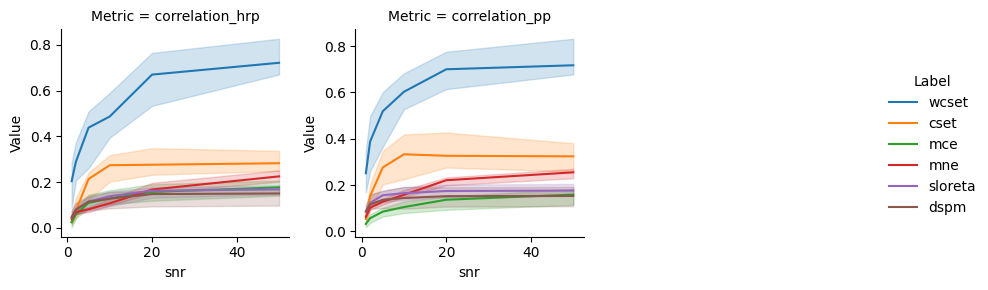

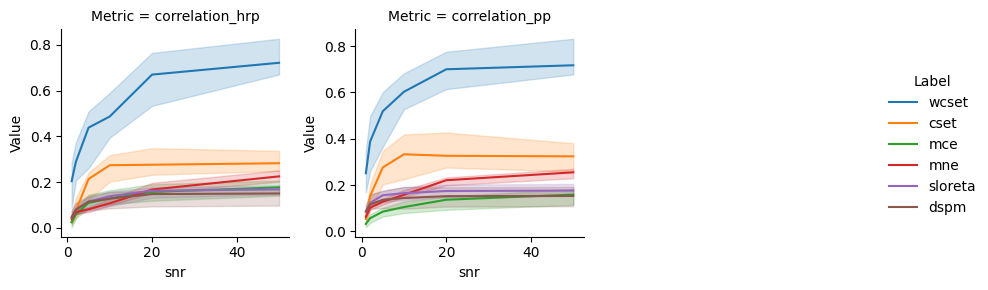

In [4]:
metrics.plot(
    metrics = ["correlation_hrp", "correlation_pp"],
    coord = "snr",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

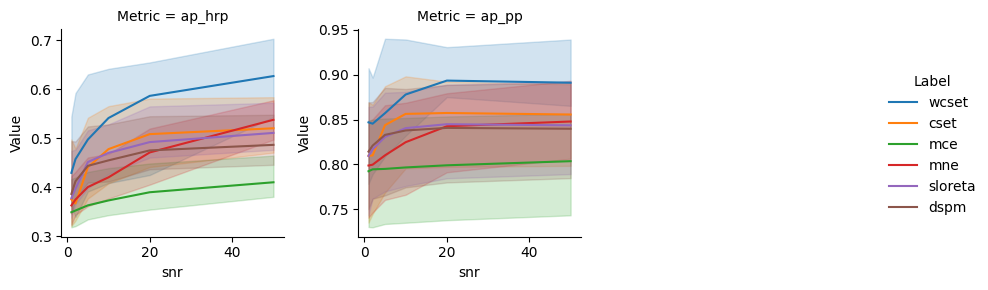

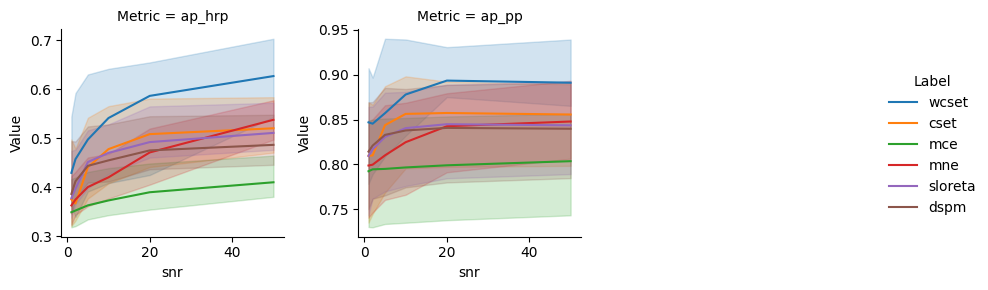

In [5]:
metrics.plot(
    metrics = ["ap_hrp", "ap_pp"],
    coord = "snr",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

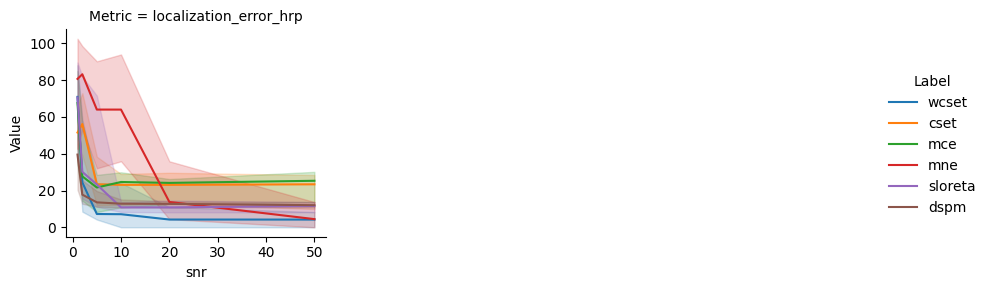

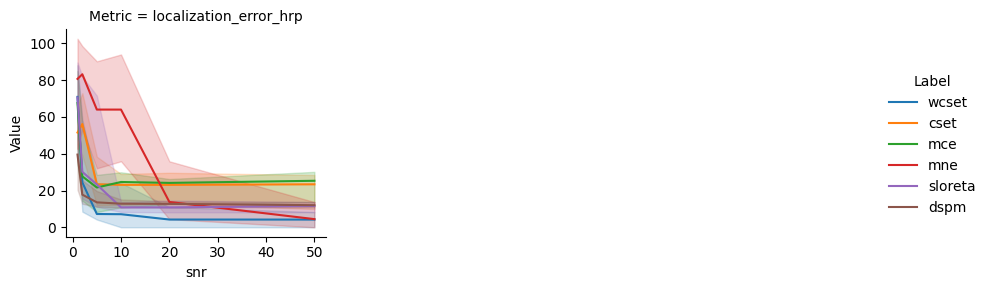

In [6]:
metrics.plot(
    metrics = ["localization_error_hrp"],
    coord = "snr",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)